# 90. Subsets II
**Difficulty:** 🟡 Medium · **Topic:** Backtracking · **Pattern:** [Subsets](README.md) · **LeetCode:** https://leetcode.com/problems/subsets-ii/

## 💡 Concepts

**Core concept(s):** the **Subsets** backtracking template plus **sort, then skip duplicates**.

**Why it applies here:**
- It is still "every subset", so it is still the include/exclude tree from [Subsets](subsets.ipynb).
- The input may repeat a value, e.g. `[1, 2, 2]`. Plain Subsets treats the two `2`s as different elements and outputs `[1, 2]` twice and `[2]` twice.
- Two subsets are the same if they hold the same values the same number of times. So for a value `v` that appears `c` times, the only real decision is **how many copies of `v`** to take: `0, 1, ..., c`.

**Key intuition:**
- **Sort first** so equal values sit next to each other in one run.
- **Include / exclude form:** including `nums[i]` moves to `i + 1` as usual (you may still take the next copy). **Excluding** `nums[i]` must skip the **whole run** of that value: once you decline one copy, declining or taking a later copy would only rebuild subsets you already have.
- **Start-index form:** at one level of the loop, a value may be picked as "the next element" only once: `if i > start and nums[i] == nums[i - 1]: continue`.
- Both forms generate each distinct subset exactly once, so no hash set is needed.

---

### 📚 What is Sorting (for grouping duplicates)?
- **Sorting** puts the list in non-decreasing order, so all copies of a value become one contiguous **run**: `[2, 1, 2]` → `[1, 2, 2]`.
- After sorting, "is this a duplicate?" is a neighbour check: `nums[j] == nums[j - 1]`, **O(1)**.
- **Cost:** **O(n log n)**, tiny next to the `2ⁿ` subsets.
- **In Python:** `sorted(nums)` returns a new list (leaves the caller's list alone); `nums.sort()` sorts in place.

### 📚 What is a Hash Set?
- A **hash set** stores unique keys. It hashes a key to a bucket, so membership tests skip any scan.
- `add` and `in` are **O(1) on average** for small keys; hashing a tuple of length `k` costs **O(k)**.
- Only **hashable** values can be keys: a `tuple` works, a `list` does not.
- **In Python:** `set()`; used by the brute force to throw away repeated subsets.

### 📚 What is a Bitmask?
- A **bitmask** is an integer whose binary digits are on/off switches.
- The integers `0 .. 2ⁿ − 1` are all `n`-bit patterns, so each picks one subset of positions: bit `i` set means "`nums[i]` is in".
- Testing bit `i` is `mask >> i & 1`, **O(1)**.
- **In Python:** plain `int` with `1 << n`, `>>`, `&`.

### 📚 What is Recursion?
- A **recursive** function solves a problem by calling itself on a smaller piece of the same problem.
- Every call gets its own frame on the **call stack**; when a call returns, Python resumes the caller exactly where it left off.
- A **base case** stops the calls (here: "every element has been decided").
- **Cost:** the stack holds one frame per level of depth, so a recursion `n` levels deep uses **O(n)** stack space.
- **In Python:** a nested `def backtrack(i): ...` that can read the outer `nums`, `path`, `out`. The default recursion limit (~1000) is far above `n <= 10`.

### 📚 What is Backtracking?
- **Backtracking** builds a candidate answer one decision at a time and **undoes** each decision after exploring it, so the same working list can be reused for every branch.
- The template is three moves: **choose** (`path.append(x)`), **explore** (recurse), **un-choose** (`path.pop()`).
- The decisions form a **recursion tree**: each node is a partial answer, each edge a decision.
- When a node is a complete answer, store a **copy**: `out.append(path[:])`. Storing `path` itself stores a reference to a list that keeps changing.
- **Cost:** proportional to the number of tree nodes times the work per node (often the `O(n)` copy).
- **In Python:** one shared `list` as `path`; `append` / `pop` at the end are both O(1).

### 📚 What is the include / exclude decision tree?
- For subsets, the decision at index `i` is binary: **include** `nums[i]` in the subset, or **exclude** it.
- After `n` binary decisions every element is decided, so the tree has exactly **2ⁿ leaves**, one per subset.
- Leaves are the only place anything is recorded (`if i == len(nums)`).
- The tree has `2ⁿ⁺¹ − 1` calls in total: the internal decision nodes plus the leaves.

### 📚 What is the start-index loop?
- The other common backtracking shape: `backtrack(start)` loops `for i in range(start, n)` and recurses with `i + 1`.
- Only moving **forward** means `[1, 2]` can be built but `[2, 1]` cannot, so no subset appears twice.
- For subsets, **every** node is an answer, so it records on entry, before the loop.
- It makes exactly one call per subset: `2ⁿ` calls.

---

**Prerequisite knowledge:**
- [Subsets](subsets.ipynb) (LC 78), the same problem without duplicates; this notebook changes only the skip.
- The same two functions, `subsets_with_dup` and `subsets_with_dup_start_index`, are in [Deep Dive 21 — Backtracking](../../../deep_dive/21_Backtracking/README.md).

## 📝 Problem

Given an integer array `nums` that **may contain duplicates**, return all possible subsets (the power set). The answer must **not** contain duplicate subsets. Return them in any order.

**Example 1**
```
nums = [1, 2, 2]  ->  [[], [1], [1, 2], [1, 2, 2], [2], [2, 2]]   (6 distinct, not 2³ = 8)
```

**Example 2**
```
nums = [0]  ->  [[], [0]]
```

**Constraints:** `1 <= nums.length <= 10`, `-10 <= nums[i] <= 10`.

**How many answers?** If the distinct values appear `c₁, c₂, ..., c_k` times, there are `(c₁+1)(c₂+1)···(c_k+1)` distinct subsets — call it `D`. For `[1, 2, 2]`: `(1+1)(2+1) = 6`. `D = 2ⁿ` when all values differ, and `D = n + 1` when they are all equal.

> Three approaches: a brute force that builds all `2ⁿ` subsets and removes repeats with a set (always `Θ(n·2ⁿ)`), then two `O(n·D)` backtracking forms that never build a repeat — include/exclude with a run skip (the pattern template) and the start-index loop with a sibling skip.

In [1]:
from typing import List
from itertools import combinations


def canon(subsets: List[List[int]]) -> List[List[int]]:
    """Order-free form for comparing answers: sort inside each subset, then sort the list of subsets."""
    return sorted(sorted(s) for s in subsets)


def reference_subsets_with_dup(nums: List[int]) -> List[List[int]]:
    """Independent ground truth: all combinations of the sorted input, de-duplicated with a set."""
    s = sorted(nums)
    return [list(t) for t in {c for k in range(len(s) + 1) for c in combinations(s, k)}]


def distinct_count(nums: List[int]) -> int:
    """D = product of (count + 1) over the distinct values."""
    d = 1
    for v in set(nums):
        d *= nums.count(v) + 1
    return d

### Approach 1 — Brute Force: every bitmask, then remove repeats with a set

**Idea:**
1. Sort `nums`, so that equal subsets come out as equal tuples (`(1, 2)` from either `2`).
2. Enumerate all `2ⁿ` masks exactly as in [Subsets](subsets.ipynb), building each subset as a tuple.
3. Keep a subset only the first time its tuple is seen.

**Time complexity:** `Θ(n·2ⁿ)` on **every** input — it builds all `2ⁿ` subsets even when only `D` of them are distinct (on `[0] * n` it builds `2ⁿ` to keep `n + 1`).

**Space complexity:** `O(n·D)` for the `seen` set of distinct tuples (on top of the `O(n·D)` output).

In [2]:
def subsets_with_dup_brute(nums: List[int]) -> List[List[int]]:
    nums = sorted(nums)                         # equal subsets -> equal tuples
    n = len(nums)
    seen, out = set(), []
    for mask in range(1 << n):                  # all 2^n position subsets, repeats included
        subset = tuple(nums[i] for i in range(n) if mask >> i & 1)
        if subset not in seen:                  # O(n) hash of the tuple
            seen.add(subset)
            out.append(list(subset))
    return out

### Approach 2 — Include / exclude, skip the whole run on exclude (optimal · pattern template)

**Idea:** the [Subsets](README.md) template with one change in the exclude branch.
1. Sort, so each value's copies form one run.
2. **Include** `nums[i]`: append, recurse into `i + 1`, pop — exactly as in Subsets. Recursing into `i + 1` lets the next copy of the same value be included too, which is how `[2, 2]` is built.
3. **Exclude** `nums[i]`: move `j` past **every** remaining copy of `nums[i]`, then recurse into `j`. Declining one copy means declining the rest; otherwise the two copies would each start their own "skip" branch and rebuild the same subsets.
4. Net effect per value with `c` copies: the branches take `c, c−1, ..., 1, 0` copies — each count once.

**Time complexity:** `O(n·D)` — every call either records a distinct subset (a leaf) or makes exactly two calls, so there are `2D − 1` calls; each leaf copies up to `n` numbers and the run skip moves `j` at most `n` steps. Worst case `D = 2ⁿ` (all distinct): `O(n·2ⁿ)`.

**Space complexity:** `O(n)` — recursion depth at most `n` plus `path` (output aside).

In [3]:
def subsets_with_dup_include_exclude(nums: List[int]) -> List[List[int]]:
    nums = sorted(nums)                         # duplicates become one adjacent run
    n = len(nums)
    out, path = [], []

    def backtrack(i: int) -> None:
        if i == n:
            out.append(path[:])                 # every value decided: record a copy
            return
        path.append(nums[i])                    # INCLUDE nums[i] (the next copy may follow)
        backtrack(i + 1)
        path.pop()                              # UN-CHOOSE

        j = i + 1
        while j < n and nums[j] == nums[i]:     # EXCLUDE nums[i] -- and every remaining
            j += 1                              # copy of it, in one jump
        backtrack(j)

    backtrack(0)
    return out

### Approach 3 — Start-index loop, skip a repeated sibling (alternate shape)

**Idea:** the start-index loop from [Subsets](subsets.ipynb) with one guard.
1. Sort. `backtrack(start)` records `path` on entry, then loops `i` from `start`, choosing `nums[i]` as the **next** element.
2. Inside one loop (one level of the tree), if `nums[i]` equals the sibling just before it, `continue`: that sibling already built every subset that continues with this value here.
3. The guard is `i > start`, **not** `i > 0`. The first pick of each level is always allowed, so after choosing the first `2` the next level may still choose the second `2` → `[2, 2]`.

**Time complexity:** `O(n·D)` — one call per distinct subset (`D` calls), each copying `path` and scanning at most `n` loop positions.

**Space complexity:** `O(n)` — recursion depth at most `n` plus `path` (output aside).

> This `if i > start and nums[i] == nums[i - 1]: continue` line is the "skip duplicates at the same level" trick, reused unchanged in Combination Sum II and Permutations II.

In [4]:
def subsets_with_dup_start_index(nums: List[int]) -> List[List[int]]:
    nums = sorted(nums)                         # duplicates become adjacent
    out, path = [], []

    def backtrack(start: int) -> None:
        out.append(path[:])                     # every node is a distinct subset
        for i in range(start, len(nums)):
            if i > start and nums[i] == nums[i - 1]:
                continue                        # SKIP: the sibling before us built this branch
            path.append(nums[i])                # CHOOSE
            backtrack(i + 1)                    # EXPLORE
            path.pop()                          # UN-CHOOSE

    backtrack(0)
    return out

In [5]:
# Correctness check
import random

tests = [
    ([1, 2, 2],        [[], [1], [1, 2], [1, 2, 2], [2], [2, 2]]),   # LeetCode example 1
    ([0],              [[], [0]]),                                   # LeetCode example 2
    ([2, 1, 2],        [[], [1], [1, 2], [1, 2, 2], [2], [2, 2]]),   # unsorted input: same answer
    ([3, 3, 3],        [[], [3], [3, 3], [3, 3, 3]]),                # all equal: n + 1 subsets
    ([1, 2, 3],        [[], [1], [2], [3], [1, 2], [1, 3], [2, 3], [1, 2, 3]]),  # no duplicates: 2^n
    ([4, 4, 4, 1, 4],  None),                                        # run of four 4s around a 1
]
for nums, exp in tests:
    if exp is None:
        exp = reference_subsets_with_dup(nums)
    a = subsets_with_dup_brute(nums)
    b = subsets_with_dup_include_exclude(nums)
    c = subsets_with_dup_start_index(nums)
    print(f"{str(nums):16} -> {len(b):2} subsets (D = {distinct_count(nums)}), include/exclude order: {b}")
    assert canon(a) == canon(b) == canon(c) == canon(exp), f"mismatch on {nums}"
    for got in (a, b, c):
        assert len(got) == len({tuple(sorted(s)) for s in got}) == distinct_count(nums)  # no repeats

print("\nstart-index order on [1, 2, 2]:", subsets_with_dup_start_index([1, 2, 2]))

# Without the skip: plain Subsets on [1, 2, 2] gives 8 lists but only 6 distinct ones
def subsets_no_skip(nums):
    out, path = [], []
    def backtrack(i):
        if i == len(nums):
            out.append(path[:]); return
        path.append(nums[i]); backtrack(i + 1); path.pop()
        backtrack(i + 1)
    backtrack(0)
    return out
plain = subsets_no_skip([1, 2, 2])
print("no skip on [1, 2, 2]:", len(plain), "lists,", len({tuple(s) for s in plain}), "distinct")
assert len(plain) == 8 and len({tuple(s) for s in plain}) == 6

# Randomised cross-check on duplicate-heavy inputs (values drawn from a small range)
rng = random.Random(90)
for _ in range(300):
    nums = [rng.randint(-2, 2) for _ in range(rng.randint(0, 10))]
    exp = canon(reference_subsets_with_dup(nums))
    for fn in (subsets_with_dup_brute, subsets_with_dup_include_exclude, subsets_with_dup_start_index):
        got = fn(nums)
        assert canon(got) == exp, (fn.__name__, nums)
        assert len(got) == distinct_count(nums), (fn.__name__, nums)
print("300 random duplicate-heavy inputs: all three approaches match itertools")

print("\nAll tests passed")

[1, 2, 2]        ->  6 subsets (D = 6), include/exclude order: [[1, 2, 2], [1, 2], [1], [2, 2], [2], []]
[0]              ->  2 subsets (D = 2), include/exclude order: [[0], []]
[2, 1, 2]        ->  6 subsets (D = 6), include/exclude order: [[1, 2, 2], [1, 2], [1], [2, 2], [2], []]
[3, 3, 3]        ->  4 subsets (D = 4), include/exclude order: [[3, 3, 3], [3, 3], [3], []]
[1, 2, 3]        ->  8 subsets (D = 8), include/exclude order: [[1, 2, 3], [1, 2], [1, 3], [1], [2, 3], [2], [3], []]
[4, 4, 4, 1, 4]  -> 10 subsets (D = 10), include/exclude order: [[1, 4, 4, 4, 4], [1, 4, 4, 4], [1, 4, 4], [1, 4], [1], [4, 4, 4, 4], [4, 4, 4], [4, 4], [4], []]

start-index order on [1, 2, 2]: [[], [1], [1, 2], [1, 2, 2], [2], [2, 2]]
no skip on [1, 2, 2]: 8 lists, 6 distinct
300 random duplicate-heavy inputs: all three approaches match itertools

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. The output can hold `2ⁿ` subsets, so doubling `n` is useless (10 → 20 multiplies the work by about 1000). The sizes grow by **one element at a time** (`n = 10, 11, ..., 16`) and the ratio column is read **per +1 element**, not per doubling (the helper's footer line is written for doubling).

| Theoretical | Ratio when `n` → `n + 1` |
|-------------|--------------------------|
| `O(n²)`       | ≈ **1.1–1.2×** (barely moves) |
| `O(2ⁿ)`       | ≈ **2×** |
| `O(n·2ⁿ)`     | ≈ **2× · (n+1)/n ≈ 2.1×** |

Two inputs, because the approaches differ only when there **are** duplicates:

1. **All distinct** (`list(range(n))`) — the worst case for every approach: `D = 2ⁿ`, so all three should grow ≈2× per element. The brute force is slower by a constant (tuple hashing), not by a different growth rate.
2. **All equal** (`[0] * n`) — the case that separates them: only `D = n + 1` subsets exist. The brute force still builds all `2ⁿ` (≈2× per element), while both backtracking forms do `O(n·D) = O(n²)` work (≈1× per element).

The log-log plot's `O(n)` / `O(n²)` reference lines are for polynomial growth; an exponential curve rises far above them.

=== 1) all distinct: D = 2^n, worst case for every approach (expect ~2x per row) ===

brute bitmask+set O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       0.74 |           n/a
       11 |       1.63 |         2.20x
       12 |       3.42 |         2.10x
       13 |       7.39 |         2.16x
       14 |      15.34 |         2.08x


       15 |      33.27 |         2.17x


       16 |      84.97 |         2.55x

include/exclude O(n*D)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       0.15 |           n/a
       11 |       0.30 |         2.08x
       12 |       0.58 |         1.91x
       13 |       1.38 |         2.37x
       14 |       3.57 |         2.60x
       15 |       6.88 |         1.93x
       16 |      13.64 |         1.98x

start-index O(n*D)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       0.21 |           n/a
       11 |       0.40 |         1.94x
       12 |       0.83 |         2.07x


       13 |       1.95 |         2.35x
       14 |       3.34 |         1.71x
       15 |       7.18 |         2.15x
       16 |      13.68 |         1.91x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


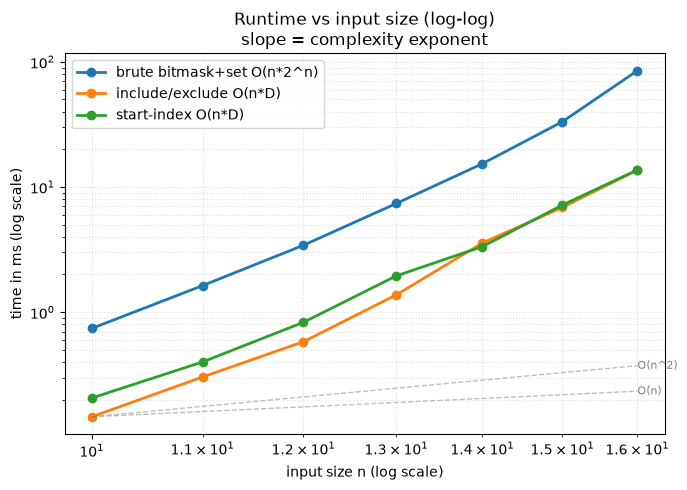


=== 2) all equal: D = n + 1, brute still builds 2^n (expect brute ~2x, backtracking ~1x) ===

brute bitmask+set O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       0.61 |           n/a
       11 |       1.33 |         2.20x
       12 |       2.85 |         2.14x
       13 |       6.00 |         2.11x
       14 |      12.23 |         2.04x
       15 |      27.29 |         2.23x
       16 |      54.24 |         1.99x

include/exclude O(n*D)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       0.00 |           n/a
       11 |       0.00 |         0.89x
       12 |       0.00 |         0.95x
       13 |       0.00 |         1.11x
       14 |       0.00 |         1.08x
       15 |       0.01 |         1.15x
       16 |       0.01 |         1.06x

start-index O(n*D)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       0.00 |           n/a
       11 |    

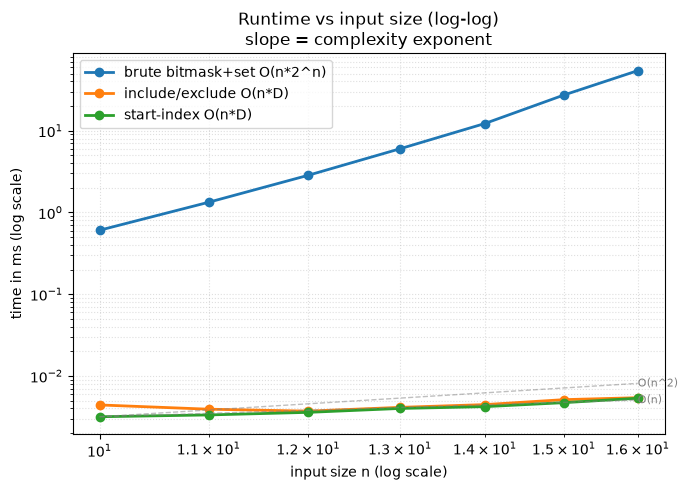

{'brute bitmask+set O(n*2^n)': [0.6052909884601831,
  1.3320829020813107,
  2.8485420625656843,
  6.0048329178243876,
  12.232500012032688,
  27.286249911412597,
  54.240375058725476],
 'include/exclude O(n*D)': [0.004416098818182945,
  0.003916909918189049,
  0.00370910856872797,
  0.004125060513615608,
  0.004458008334040642,
  0.005124951712787151,
  0.005415990017354488],
 'start-index O(n*D)': [0.0031669624149799347,
  0.0033329706639051437,
  0.003583962097764015,
  0.00400003045797348,
  0.004208995960652828,
  0.004708999767899513,
  0.005332985892891884]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

solutions = {
    "brute bitmask+set O(n*2^n)": subsets_with_dup_brute,
    "include/exclude O(n*D)": subsets_with_dup_include_exclude,
    "start-index O(n*D)": subsets_with_dup_start_index,
}
sizes = list(range(10, 17))           # +1 element per row (not doubling)

print("=== 1) all distinct: D = 2^n, worst case for every approach (expect ~2x per row) ===")
def make_worst_case(n):
    return (list(range(n)),)
benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

print("\n=== 2) all equal: D = n + 1, brute still builds 2^n (expect brute ~2x, backtracking ~1x) ===")
def make_all_equal(n):
    return ([0] * n,)
benchmark(solutions, make_all_equal, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Subsets](README.md) — the include/exclude template with one change: sort first, and let the **exclude** branch jump past the whole run of equal values (`while j < n and nums[j] == nums[i]: j += 1`), so each value's copy count is chosen once.
- **Sort + skip duplicates at the same level:** in the start-index loop, `if i > start and nums[i] == nums[i - 1]: continue`. Two copies of a value in one loop would start identical subtrees; only the first may.
- **Generate unique, don't filter later:** the set-based brute force always pays for all `2ⁿ` subsets; the skip makes the work proportional to the `D` answers that exist (measured: ≈2× vs ≈1× per element on `[0] * n`).
- **Signal:** "may contain duplicates" + "the solution set must not contain duplicate subsets / combinations".
- **Related problems:** Subsets ([subsets.ipynb](subsets.ipynb), the same template without the skip), Combination Sum II (LC 40: same skip plus a target), Permutations II (LC 47: duplicates in an order-matters search).
- **Common pitfalls:**
  1. Forgetting to sort — the neighbour check `nums[i] == nums[i - 1]` only finds duplicates that are adjacent.
  2. Writing `i > 0` instead of `i > start` — it forbids the second copy everywhere, so `[2, 2]` is never built.
  3. In include/exclude, skipping the run on the **include** branch — then a value can never be taken twice.
  4. Deduplicating with a set of lists — lists are unhashable; and a set of tuples still costs the full `2ⁿ`.